Training Baseline GAN...
Epoch 1/50 | Generator Loss: 7.3831 | Discriminator Loss: 0.1201
Epoch 2/50 | Generator Loss: 5.4053 | Discriminator Loss: 0.3094
Epoch 3/50 | Generator Loss: 7.4731 | Discriminator Loss: 0.2697
Epoch 4/50 | Generator Loss: 5.4931 | Discriminator Loss: 0.1824
Epoch 5/50 | Generator Loss: 4.9968 | Discriminator Loss: 0.1811
Epoch 6/50 | Generator Loss: 6.6441 | Discriminator Loss: 0.0951
Epoch 7/50 | Generator Loss: 7.1554 | Discriminator Loss: 0.1522
Epoch 8/50 | Generator Loss: 6.8616 | Discriminator Loss: 0.0937
Epoch 9/50 | Generator Loss: 8.1544 | Discriminator Loss: 0.0770
Epoch 10/50 | Generator Loss: 6.9817 | Discriminator Loss: 0.1318
Epoch 11/50 | Generator Loss: 7.4360 | Discriminator Loss: 0.0929
Epoch 12/50 | Generator Loss: 9.0296 | Discriminator Loss: 0.0890
Epoch 13/50 | Generator Loss: 5.9659 | Discriminator Loss: 0.1826
Epoch 14/50 | Generator Loss: 3.6451 | Discriminator Loss: 0.3314
Epoch 15/50 | Generator Loss: 4.9003 | Discriminator Loss: 0

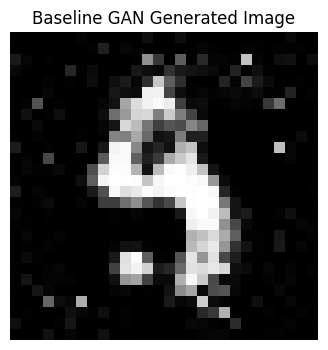

In [7]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

# =========================
# SETTINGS
# =========================

EPOCHS = 50
BATCH_SIZE = 128
NOISE_DIM = 100

# =========================
# LOAD MNIST DATASET
# =========================

(x_train, _), (_, _) = mnist.load_data()

# Normalize images to [-1, 1]
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)

dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(60000)
    .batch(BATCH_SIZE)
)

# =========================
# GENERATOR
# =========================

def build_generator():

    model = tf.keras.Sequential([
        layers.Input(shape=(NOISE_DIM,)),

        layers.Dense(256),
        layers.LeakyReLU(0.2),

        layers.Dense(512),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),

        layers.Dense(1024),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),

        layers.Dense(28 * 28, activation="tanh"),

        layers.Reshape((28, 28, 1))
    ])

    return model


# =========================
# DISCRIMINATOR
# =========================

def build_discriminator():

    model = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Flatten(),

        layers.Dense(512),
        layers.LeakyReLU(0.2),

        layers.Dense(256),
        layers.LeakyReLU(0.2),

        layers.Dense(1, activation="sigmoid")
    ])

    return model


generator = build_generator()
discriminator = build_discriminator()

# =========================
# LOSS AND OPTIMIZER
# =========================

loss_function = tf.keras.losses.BinaryCrossentropy()

g_optimizer = tf.keras.optimizers.Adam(0.0002)
d_optimizer = tf.keras.optimizers.Adam(0.0002)


# =========================
# TRAINING STEP
# =========================

@tf.function
def train_step(real_images):

    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal(
        [batch_size, NOISE_DIM]
    )

    # ---------------------
    # Train Discriminator
    # ---------------------

    with tf.GradientTape() as tape:

        fake_images = generator(
            noise,
            training=True
        )

        real_output = discriminator(
            real_images,
            training=True
        )

        fake_output = discriminator(
            fake_images,
            training=True
        )

        real_loss = loss_function(
            tf.ones_like(real_output),
            real_output
        )

        fake_loss = loss_function(
            tf.zeros_like(fake_output),
            fake_output
        )

        d_loss = real_loss + fake_loss

    d_gradients = tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    d_optimizer.apply_gradients(
        zip(
            d_gradients,
            discriminator.trainable_variables
        )
    )

    # ---------------------
    # Train Generator
    # ---------------------

    with tf.GradientTape() as tape:

        fake_images = generator(
            noise,
            training=True
        )

        fake_output = discriminator(
            fake_images,
            training=True
        )

        g_loss = loss_function(
            tf.ones_like(fake_output),
            fake_output
        )

    g_gradients = tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(
            g_gradients,
            generator.trainable_variables
        )
    )

    return g_loss, d_loss


# =========================
# TRAINING
# =========================

print("Training Baseline GAN...")

for epoch in range(EPOCHS):

    for images in dataset:

        g_loss, d_loss = train_step(images)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {g_loss:.4f} | "
        f"Discriminator Loss: {d_loss:.4f}"
    )


# =========================
# GENERATE IMAGE
# =========================

noise = tf.random.normal(
    [1, NOISE_DIM]
)

generated_image = generator(
    noise,
    training=False
)[0]

# Convert [-1,1] to [0,1]
generated_image = (generated_image + 1) / 2

plt.figure(figsize=(4, 4))

plt.imshow(
    generated_image[:, :, 0],
    cmap="gray"
)

plt.title("Baseline GAN Generated Image")
plt.axis("off")
plt.show()

Training Conditional GAN...
Epoch 1/50 | Generator Loss: 9.1521 | Discriminator Loss: 0.0970
Epoch 2/50 | Generator Loss: 11.8694 | Discriminator Loss: 0.2144
Epoch 3/50 | Generator Loss: 5.4834 | Discriminator Loss: 0.1614
Epoch 4/50 | Generator Loss: 7.5826 | Discriminator Loss: 0.1879
Epoch 5/50 | Generator Loss: 7.9251 | Discriminator Loss: 0.0573
Epoch 6/50 | Generator Loss: 6.7799 | Discriminator Loss: 0.0377
Epoch 7/50 | Generator Loss: 9.1091 | Discriminator Loss: 0.0446
Epoch 8/50 | Generator Loss: 7.9435 | Discriminator Loss: 0.1357
Epoch 9/50 | Generator Loss: 8.1736 | Discriminator Loss: 0.2064
Epoch 10/50 | Generator Loss: 8.0154 | Discriminator Loss: 0.1371
Epoch 11/50 | Generator Loss: 5.3163 | Discriminator Loss: 0.1666
Epoch 12/50 | Generator Loss: 6.5234 | Discriminator Loss: 0.1885
Epoch 13/50 | Generator Loss: 5.9476 | Discriminator Loss: 0.1922
Epoch 14/50 | Generator Loss: 7.9959 | Discriminator Loss: 0.1348
Epoch 15/50 | Generator Loss: 6.3258 | Discriminator Los

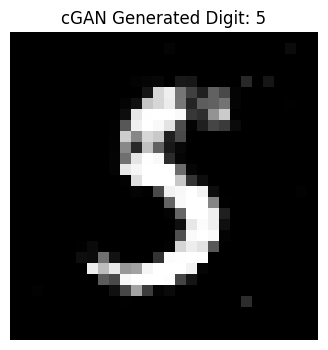


Enter a digit (0-9) or 'q' to quit: 4


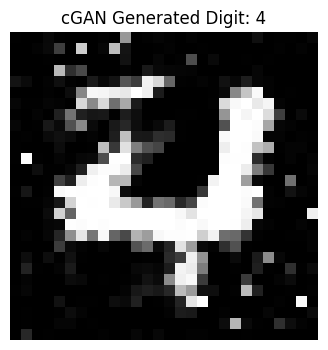


Enter a digit (0-9) or 'q' to quit: 3


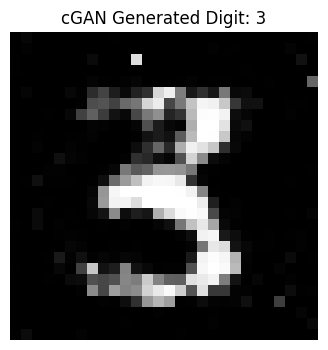


Enter a digit (0-9) or 'q' to quit: 8


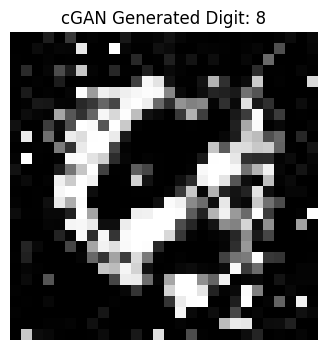


Enter a digit (0-9) or 'q' to quit: 9


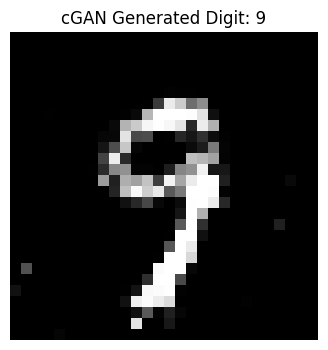


Enter a digit (0-9) or 'q' to quit: 7


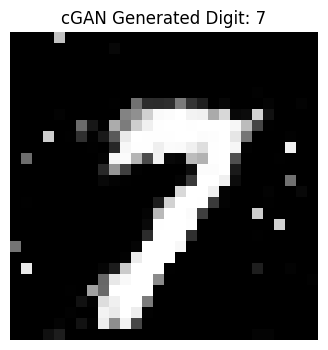


Enter a digit (0-9) or 'q' to quit: 6


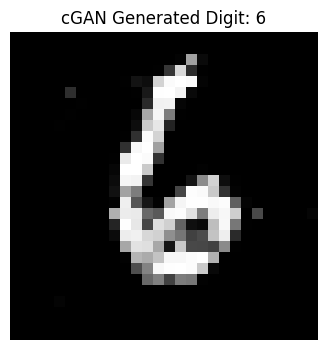

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

# =========================
# SETTINGS
# =========================

EPOCHS = 50
BATCH_SIZE = 128
NOISE_DIM = 100

# =========================
# LOAD MNIST
# =========================

(x_train, y_train), (_, _) = mnist.load_data()

# Normalize
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)

# Convert labels to one-hot
y_train = tf.keras.utils.to_categorical(
    y_train,
    num_classes=10
)

dataset = (
    tf.data.Dataset
    .from_tensor_slices(
        (x_train, y_train)
    )
    .shuffle(60000)
    .batch(BATCH_SIZE)
)

# =========================
# cGAN GENERATOR
# =========================

def build_generator():

    noise_input = layers.Input(
        shape=(NOISE_DIM,)
    )

    label_input = layers.Input(
        shape=(10,)
    )

    # Combine noise and label
    x = layers.Concatenate()([
        noise_input,
        label_input
    ])

    x = layers.Dense(256)(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Dense(512)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Dense(1024)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Dense(
        28 * 28,
        activation="tanh"
    )(x)

    output = layers.Reshape(
        (28, 28, 1)
    )(x)

    return tf.keras.Model(
        [noise_input, label_input],
        output
    )


# =========================
# cGAN DISCRIMINATOR
# =========================

def build_discriminator():

    image_input = layers.Input(
        shape=(28, 28, 1)
    )

    label_input = layers.Input(
        shape=(10,)
    )

    x = layers.Flatten()(image_input)

    # Combine image and label
    x = layers.Concatenate()([
        x,
        label_input
    ])

    x = layers.Dense(512)(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Dense(256)(x)
    x = layers.LeakyReLU(0.2)(x)

    output = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return tf.keras.Model(
        [image_input, label_input],
        output
    )


generator = build_generator()
discriminator = build_discriminator()

# =========================
# LOSS
# =========================

loss_function = tf.keras.losses.BinaryCrossentropy()

g_optimizer = tf.keras.optimizers.Adam(0.0002)
d_optimizer = tf.keras.optimizers.Adam(0.0002)


# =========================
# TRAINING STEP
# =========================

@tf.function
def train_step(real_images, real_labels):

    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal(
        [batch_size, NOISE_DIM]
    )

    # ---------------------
    # Train Discriminator
    # ---------------------

    with tf.GradientTape() as tape:

        fake_images = generator(
            [noise, real_labels],
            training=True
        )

        real_output = discriminator(
            [real_images, real_labels],
            training=True
        )

        fake_output = discriminator(
            [fake_images, real_labels],
            training=True
        )

        real_loss = loss_function(
            tf.ones_like(real_output),
            real_output
        )

        fake_loss = loss_function(
            tf.zeros_like(fake_output),
            fake_output
        )

        d_loss = real_loss + fake_loss

    d_gradients = tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    d_optimizer.apply_gradients(
        zip(
            d_gradients,
            discriminator.trainable_variables
        )
    )

    # ---------------------
    # Train Generator
    # ---------------------

    with tf.GradientTape() as tape:

        fake_images = generator(
            [noise, real_labels],
            training=True
        )

        fake_output = discriminator(
            [fake_images, real_labels],
            training=True
        )

        g_loss = loss_function(
            tf.ones_like(fake_output),
            fake_output
        )

    g_gradients = tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(
            g_gradients,
            generator.trainable_variables
        )
    )

    return g_loss, d_loss


# =========================
# TRAIN cGAN
# =========================

print("Training Conditional GAN...")

for epoch in range(EPOCHS):

    for images, labels in dataset:

        g_loss, d_loss = train_step(
            images,
            labels
        )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {g_loss:.4f} | "
        f"Discriminator Loss: {d_loss:.4f}"
    )


# ==================================================
# USER INPUT FOR cGAN
# ==================================================

print("\n==============================")
print("       cGAN DIGIT GENERATOR")
print("==============================")

while True:

    user_input = input(
        "\nEnter a digit (0-9) or 'q' to quit: "
    )

    if user_input.lower() == "q":
        print("Exiting...")
        break

    try:
        digit = int(user_input)

        if digit < 0 or digit > 9:
            print("Please enter a digit between 0 and 9.")
            continue

    except ValueError:
        print("Invalid input. Enter a digit from 0 to 9.")
        continue

    # Create one-hot label AS A TENSOR
    label = tf.one_hot(
        [digit],
        depth=10,
        dtype=tf.float32
    )

    # Generate random noise
    noise = tf.random.normal(
        shape=(1, NOISE_DIM),
        dtype=tf.float32
    )

    # Generate requested digit
    generated_image = generator(
        [noise, label],
        training=False
    )

    # Take first image
    generated_image = generated_image[0]

    # Convert [-1, 1] to [0, 1]
    generated_image = (
        generated_image + 1
    ) / 2

    # Display
    plt.figure(figsize=(4, 4))

    plt.imshow(
        generated_image[:, :, 0],
        cmap="gray"
    )

    plt.title(
        f"cGAN Generated Digit: {digit}"
    )

    plt.axis("off")
    plt.show()

Training DCGAN...
Epoch 1/20 | Generator Loss: 3.5949 | Discriminator Loss: 0.0925
Epoch 2/20 | Generator Loss: 5.4962 | Discriminator Loss: 0.0098
Epoch 3/20 | Generator Loss: 6.7806 | Discriminator Loss: 0.0037
Epoch 4/20 | Generator Loss: 7.4168 | Discriminator Loss: 0.0057
Epoch 5/20 | Generator Loss: 7.9698 | Discriminator Loss: 0.0019
Epoch 6/20 | Generator Loss: 8.5633 | Discriminator Loss: 0.0004
Epoch 7/20 | Generator Loss: 8.6326 | Discriminator Loss: 0.0004
Epoch 8/20 | Generator Loss: 9.7561 | Discriminator Loss: 0.0002
Epoch 9/20 | Generator Loss: 6.6917 | Discriminator Loss: 0.0020
Epoch 10/20 | Generator Loss: 8.1512 | Discriminator Loss: 0.0022
Epoch 11/20 | Generator Loss: 8.3133 | Discriminator Loss: 0.0005
Epoch 12/20 | Generator Loss: 9.3165 | Discriminator Loss: 0.0002
Epoch 13/20 | Generator Loss: 9.2259 | Discriminator Loss: 0.0002
Epoch 14/20 | Generator Loss: 6.4555 | Discriminator Loss: 0.1396
Epoch 15/20 | Generator Loss: 1.5522 | Discriminator Loss: 1.0706
E

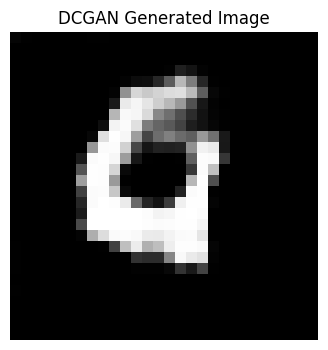

In [4]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

# =========================
# SETTINGS
# =========================

EPOCHS = 20
BATCH_SIZE = 128
NOISE_DIM = 100

# =========================
# LOAD MNIST
# =========================

(x_train, _), (_, _) = mnist.load_data()

# Normalize to [-1,1]
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

# Add channel
x_train = np.expand_dims(
    x_train,
    axis=-1
)

dataset = (
    tf.data.Dataset
    .from_tensor_slices(x_train)
    .shuffle(60000)
    .batch(BATCH_SIZE)
)

# =========================
# DCGAN GENERATOR
# =========================

def build_generator():

    model = tf.keras.Sequential([

        layers.Input(
            shape=(NOISE_DIM,)
        ),

        layers.Dense(
            7 * 7 * 256
        ),

        layers.BatchNormalization(),

        layers.LeakyReLU(0.2),

        layers.Reshape(
            (7, 7, 256)
        ),

        # 7x7 -> 14x14
        layers.Conv2DTranspose(
            128,
            kernel_size=4,
            strides=2,
            padding="same"
        ),

        layers.BatchNormalization(),

        layers.LeakyReLU(0.2),

        # 14x14 -> 28x28
        layers.Conv2DTranspose(
            64,
            kernel_size=4,
            strides=2,
            padding="same"
        ),

        layers.BatchNormalization(),

        layers.LeakyReLU(0.2),

        # Final image
        layers.Conv2D(
            1,
            kernel_size=7,
            padding="same",
            activation="tanh"
        )
    ])

    return model


# =========================
# DCGAN DISCRIMINATOR
# =========================

def build_discriminator():

    model = tf.keras.Sequential([

        layers.Input(
            shape=(28, 28, 1)
        ),

        layers.Conv2D(
            64,
            kernel_size=4,
            strides=2,
            padding="same"
        ),

        layers.LeakyReLU(0.2),

        layers.Dropout(0.3),

        # 28x28 -> 14x14
        layers.Conv2D(
            128,
            kernel_size=4,
            strides=2,
            padding="same"
        ),

        layers.LeakyReLU(0.2),

        layers.Dropout(0.3),

        layers.Flatten(),

        layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    return model


generator = build_generator()
discriminator = build_discriminator()

# =========================
# LOSS
# =========================

loss_function = tf.keras.losses.BinaryCrossentropy()

g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002
)

d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002
)


# =========================
# TRAINING STEP
# =========================

@tf.function
def train_step(real_images):

    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal(
        [batch_size, NOISE_DIM]
    )

    # ---------------------
    # Train Discriminator
    # ---------------------

    with tf.GradientTape() as tape:

        fake_images = generator(
            noise,
            training=True
        )

        real_output = discriminator(
            real_images,
            training=True
        )

        fake_output = discriminator(
            fake_images,
            training=True
        )

        real_loss = loss_function(
            tf.ones_like(real_output),
            real_output
        )

        fake_loss = loss_function(
            tf.zeros_like(fake_output),
            fake_output
        )

        d_loss = real_loss + fake_loss

    d_gradients = tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    d_optimizer.apply_gradients(
        zip(
            d_gradients,
            discriminator.trainable_variables
        )
    )

    # ---------------------
    # Train Generator
    # ---------------------

    with tf.GradientTape() as tape:

        fake_images = generator(
            noise,
            training=True
        )

        fake_output = discriminator(
            fake_images,
            training=True
        )

        g_loss = loss_function(
            tf.ones_like(fake_output),
            fake_output
        )

    g_gradients = tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(
            g_gradients,
            generator.trainable_variables
        )
    )

    return g_loss, d_loss


# =========================
# TRAIN DCGAN
# =========================

print("Training DCGAN...")

for epoch in range(EPOCHS):

    for images in dataset:

        g_loss, d_loss = train_step(images)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {g_loss:.4f} | "
        f"Discriminator Loss: {d_loss:.4f}"
    )


# =========================
# GENERATE IMAGE
# =========================

noise = tf.random.normal(
    [1, NOISE_DIM]
)

generated_image = generator(
    noise,
    training=False
)[0]

# Convert [-1,1] to [0,1]
generated_image = (
    generated_image + 1
) / 2

plt.figure(figsize=(4, 4))

plt.imshow(
    generated_image[:, :, 0],
    cmap="gray"
)

plt.title("DCGAN Generated Image")

plt.axis("off")

plt.show()